# Fairness, error rates and calibration

Audit separate targets; sensitive-column exclusion does not remove proxies.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))


In [2]:
import json, pandas as pd
from IPython.display import display, Image
results=json.loads((ROOT/'reports/results.json').read_text())

In [3]:
from src.fairness import disparities
for scope in ['hr','adult']:
    display(pd.DataFrame(results[scope]['gender_audit']))
    display(disparities(results[scope]['gender_audit']))
display(pd.DataFrame(results['adult']['race_audit']))

,group,n,actual_positive_n,predicted_positive_n,tn,fp,fn,tp,selection_rate,selection_rate_ci95,tpr,tpr_ci95,fpr,fpr_ci95,fnr,fnr_ci95,brier,small_group
0,Female,116,16,21,89,11,6,10,0.181034,"[0.12156680637577684, 0.2609507236326123]",0.625000,"[0.386410405455033, 0.81518767441136]",0.110000,"[0.06254196357064666, 0.18631296503080064]",0.375000,"[0.18481232558864005, 0.613589594544967]",0.091226,False
1,Male,178,31,27,134,13,17,14,0.151685,"[0.10638925612452374, 0.21169804473533635]",0.451613,"[0.291617359805204, 0.6222783236264506]",0.088435,"[0.05241011033720432, 0.14542315814216394]",0.548387,"[0.37772167637354936, 0.7083826401947959]",0.109714,False


{'selection_rate_difference': 0.029349089500193715,
 'tpr_difference': 0.17338709677419356,
 'fpr_difference': 0.021564625850340136,
 'fnr_difference': -0.1733870967741935,
 'selection_rate_ratio': 1.193486590038314}

,group,n,actual_positive_n,predicted_positive_n,tn,fp,fn,tp,selection_rate,selection_rate_ci95,tpr,tpr_ci95,fpr,fpr_ci95,fnr,fnr_ci95,brier,small_group
0,Female,5421,590,627,4604,227,190,400,0.115661,"[0.1074185696509354, 0.12444838321189279]",0.677966,"[0.6392163022449038, 0.7144134366033026]",0.046988,"[0.041372422236131356, 0.0533238491349613]",0.322034,"[0.2855865633966973, 0.360783697755096]",0.053827,False
1,Male,10860,3256,4034,6119,1485,707,2549,0.371455,"[0.3624141174316087, 0.38058655037240374]",0.782862,"[0.7683717756509882, 0.7966863792527712]",0.195292,"[0.18653651123780354, 0.204355106958677]",0.217138,"[0.20331362074722895, 0.23162822434901195]",0.121022,False


{'selection_rate_difference': -0.25579356319449326,
 'tpr_difference': -0.10489630616749268,
 'fpr_difference': -0.14830375040383914,
 'fnr_difference': 0.10489630616749257,
 'selection_rate_ratio': 0.3113737986385233}

,group,n,actual_positive_n,predicted_positive_n,tn,fp,fn,tp,selection_rate,selection_rate_ci95,tpr,tpr_ci95,fpr,fpr_ci95,fnr,fnr_ci95,brier,small_group
0,Amer-Indian-Eskimo,159,19,28,129,11,2,17,0.176101,"[0.12474094423724649, 0.2427420005488589]",0.894737,"[0.6860591728889169, 0.9706414397011289]",0.078571,"[0.04443737597511979, 0.13521499290766995]",0.105263,"[0.029358560298871045, 0.31394082711108295]",0.058510,False
1,Asian-Pac-Islander,480,133,169,282,65,29,104,0.352083,"[0.3106837472628554, 0.3958316878837975]",0.781955,"[0.7044048343917942, 0.8436746778141812]",0.187320,"[0.14977349721087585, 0.23171351196581574]",0.218045,"[0.15632532218581874, 0.2955951656082057]",0.117199,False
2,Black,1561,179,222,1290,92,49,130,0.142217,"[0.12576735326774122, 0.1604223155298883]",0.726257,"[0.6566997900555979, 0.7863069575520868]",0.066570,"[0.05459257295056026, 0.08095067958031789]",0.273743,"[0.2136930424479132, 0.34330020994440213]",0.056183,False
3,Other,135,25,25,105,5,5,20,0.185185,"[0.12869783265528179, 0.25909310009649217]",0.800000,"[0.6086904963046025, 0.9113941531319725]",0.045455,"[0.01956946065923517, 0.102015935066367]",0.200000,"[0.0886058468680277, 0.39130950369539763]",0.072426,False
4,White,13946,3490,4217,8917,1539,812,2678,0.302381,"[0.2948131741888471, 0.31005688714689095]",0.767335,"[0.7530277033585904, 0.7810549165865766]",0.147188,"[0.14052688404947827, 0.1541086963227083]",0.232665,"[0.21894508341342353, 0.24697229664140966]",0.103475,False


,group,bin,n,mean_probability,observed_positive_share
0,Female,"(-0.001, 0.2]",4335,0.043625,0.022837
1,Female,"(0.2, 0.4]",587,0.285184,0.231687
2,Female,"(0.4, 0.6]",273,0.493691,0.567766
3,Female,"(0.6, 0.8]",184,0.675222,0.858696
4,Female,"(0.8, 1.0]",42,0.852094,1.000000
5,Male,"(-0.001, 0.2]",4810,0.061324,0.041164
6,Male,"(0.2, 0.4]",2756,0.299313,0.277939
7,Male,"(0.4, 0.6]",1360,0.483490,0.502206
8,Male,"(0.6, 0.8]",1352,0.690589,0.765533
9,Male,"(0.8, 1.0]",582,0.873342,0.986254


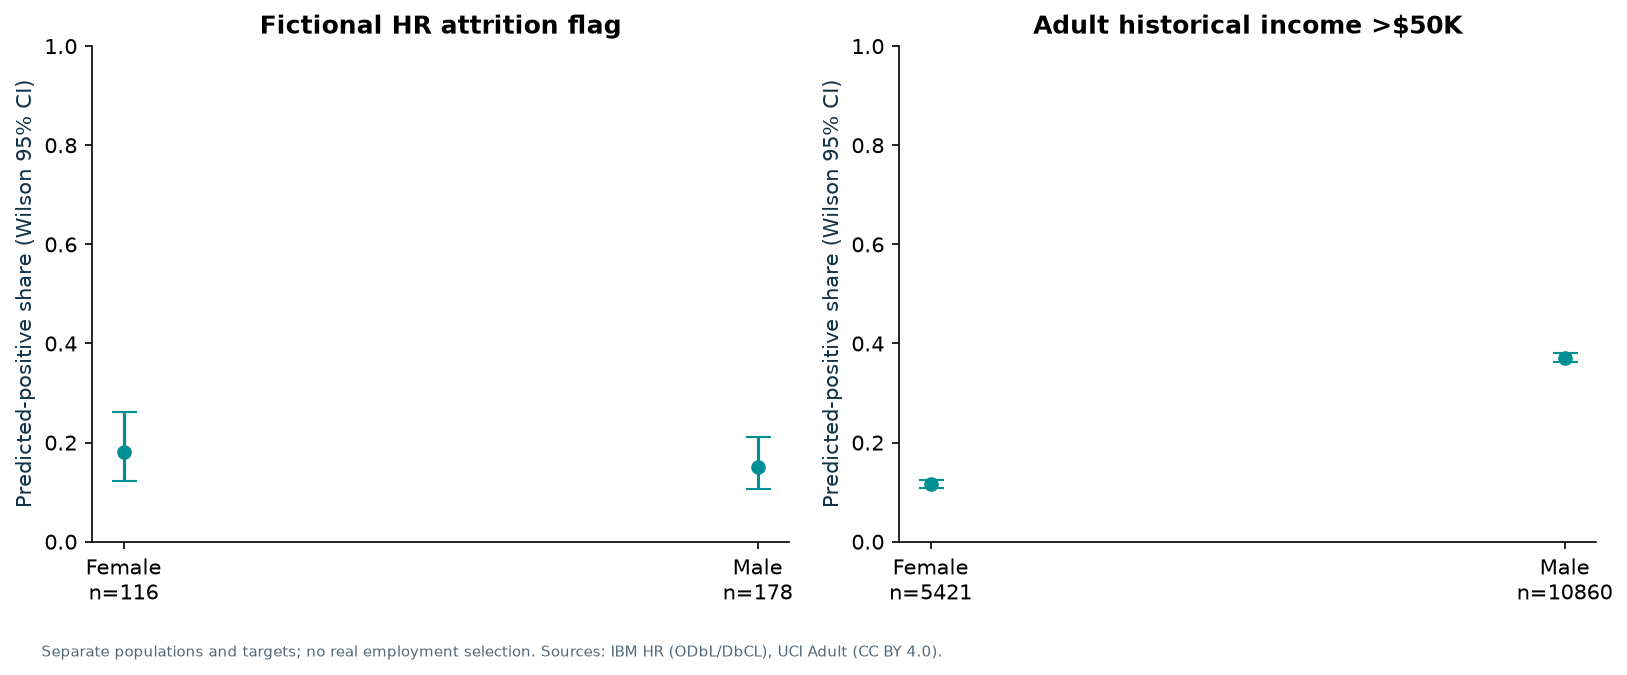

Wilson intervals quantify sampling uncertainty, not historical measurement bias. Undefined rates remain null. No legal discrimination determination.


In [4]:
display(pd.read_csv(ROOT/'data/processed/adult_calibration.csv'))
display(Image(filename=str(ROOT/'figures/fairness_selection.png')))
print('Wilson intervals quantify sampling uncertainty, not historical measurement bias. Undefined rates remain null. No legal discrimination determination.')